# Encoding and correlation analysis

In [7]:
import sys
sys.path.append('..')

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.config import DATA_PATH
from src.imbalance import create_imbalance
from src.features import encode_features

sns.set_theme(style='whitegrid')

target = 'Performance_Score'
df = pd.read_csv(DATA_PATH)
df_imb = create_imbalance(df, target)

X = encode_features(df_imb, target)
y = df_imb[target]
print(X.shape)
X.head()

(64271, 34)


,Age,Years_At_Company,Education_Level,Monthly_Salary,Work_Hours_Per_Week,Projects_Handled,Overtime_Hours,Sick_Days,Remote_Work_Frequency,Team_Size,...,Gender_Female,Gender_Male,Gender_Other,Job_Title_Analyst,Job_Title_Consultant,Job_Title_Developer,Job_Title_Engineer,Job_Title_Manager,Job_Title_Specialist,Job_Title_Technician
0,54,4,1,8400.0,56,15,22,8,0,17,...,0,1,0,0,0,0,0,1,0,0
1,50,1,0,4550.0,32,29,26,3,25,3,...,1,0,0,0,0,0,0,0,0,1
2,53,3,1,6000.0,34,19,15,10,25,5,...,0,1,0,0,0,1,0,0,0,0
3,26,2,1,5600.0,54,5,14,2,75,11,...,0,1,0,1,0,0,0,0,0,0
4,58,2,1,5250.0,52,1,8,0,75,1,...,0,1,0,0,0,0,0,0,0,1


## Encoding choices

- `Education_Level`: ordinal (High School < Bachelor < Master < PhD), the order is real.
- `Department`, `Gender`, `Job_Title`: one-hot, they have no order. A `LabelEncoder` would invent an alphabetical order and make the correlation meaningless.
- `Hire_Date`: parsed as a date, only the year is kept.
- `Resigned`: 0/1. `Employee_ID` is dropped (identifier).

In [8]:
assert X.select_dtypes(exclude='number').empty
assert not X.isna().any().any()

## Correlation with the target

Pearson measures linear relations. Spearman only uses ranks, which suits an ordinal target. For one-hot columns, each dummy is compared with the score on its own.

In [9]:
corr = pd.DataFrame({
    'pearson': X.corrwith(y),
    'spearman': X.corrwith(y, method='spearman'),
})
corr = corr.reindex(corr['pearson'].abs().sort_values(ascending=False).index)
corr.round(4)

,pearson,spearman
Monthly_Salary,0.3520,0.3311
Work_Hours_Per_Week,-0.0104,-0.0092
Job_Title_Specialist,0.0091,0.0094
Department_Marketing,-0.0082,-0.0084
Sick_Days,-0.0075,-0.0079
Job_Title_Engineer,-0.0073,-0.0078
Job_Title_Technician,-0.0069,-0.0060
Department_Engineering,0.0065,0.0057
Promotions,-0.0062,-0.0056
Gender_Female,-0.0061,-0.0074


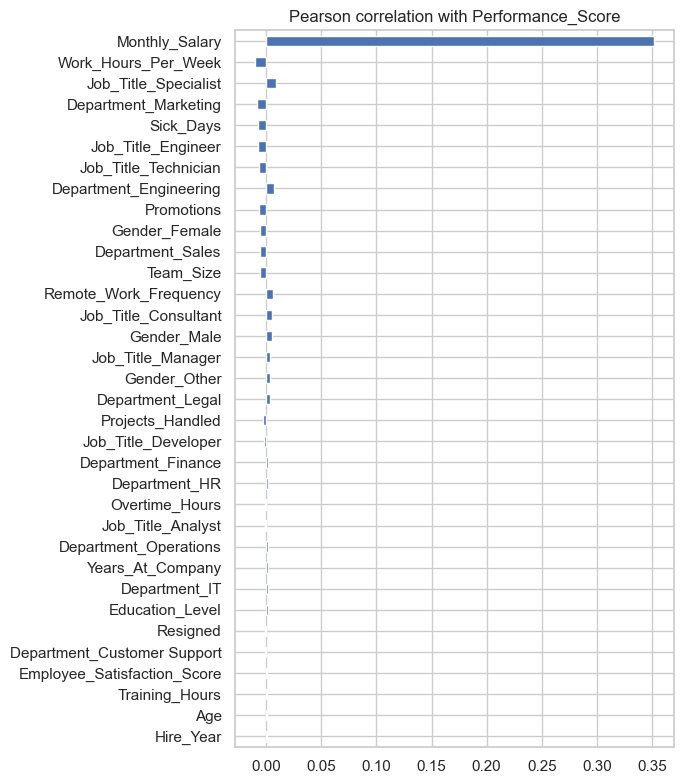

In [10]:
fig, ax = plt.subplots(figsize=(7, 8))
corr['pearson'].iloc[::-1].plot.barh(ax=ax)
ax.set_title('Pearson correlation with Performance_Score')
plt.tight_layout()
plt.show()

## Correlation between features

Heatmap on the non-dummy columns, then every pair above 0.8 in absolute value (redundant features).

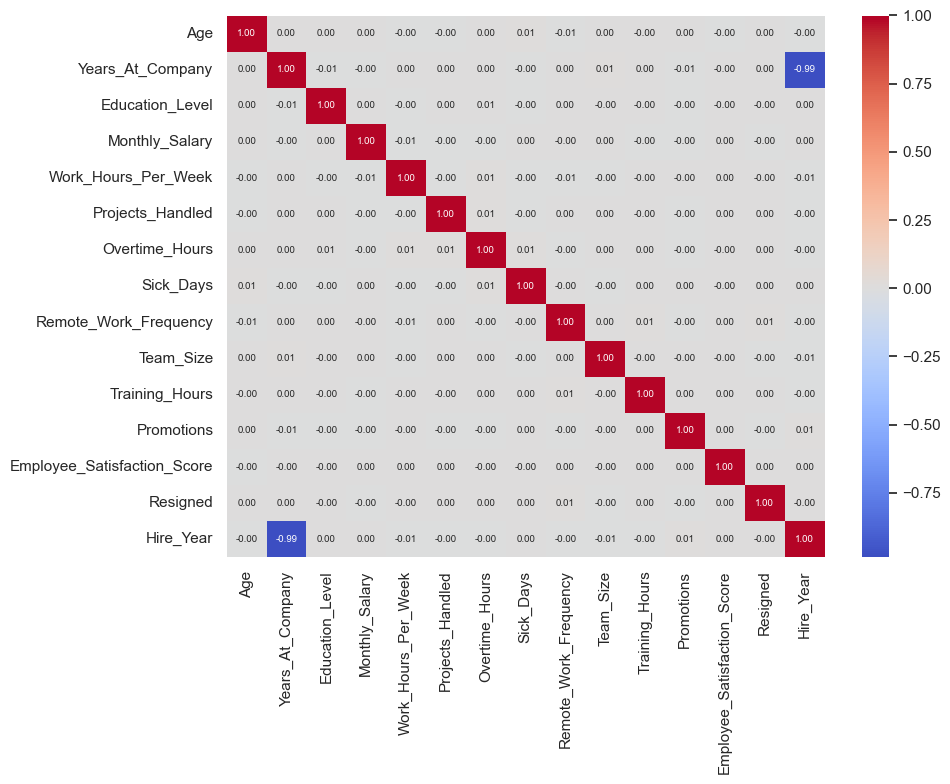

In [11]:
dummy_cols = [c for c in X.columns if c.startswith(('Department_', 'Gender_', 'Job_Title_'))]
base_cols = [c for c in X.columns if c not in dummy_cols]

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(X[base_cols].corr(), cmap='coolwarm', center=0, annot=True, fmt='.2f', annot_kws={'size': 7}, ax=ax)
plt.tight_layout()
plt.show()

In [12]:
c = X.corr().abs()
pairs = c.where(~pd.DataFrame(
    [[i >= j for j in range(len(c))] for i in range(len(c))],
    index=c.index, columns=c.columns)).stack()
pairs[pairs > 0.8].sort_values(ascending=False)

Years_At_Company  Hire_Year      0.98696
Gender_Female     Gender_Male    0.92408
dtype: float64

## What Pearson does not show

In the EDA, `Monthly_Salary` looked like a deterministic function of `Job_Title` and `Performance_Score`. If salary = base(job) × (1 + 0.1 × score), then dividing the salary by (1 + 0.1 × score) must give a single value per job title.

In [13]:
ratio = (df['Monthly_Salary'] / (1 + 0.1 * df[target])).round(2)
check = ratio.groupby(df['Job_Title']).agg(['nunique', 'min', 'max'])
check

,nunique,min,max
Job_Title,,,
Analyst,1,4000.0,4000.0
Consultant,1,5500.0,5500.0
Developer,1,5000.0,5000.0
Engineer,1,6000.0,6000.0
Manager,1,6000.0,6000.0
Specialist,1,4500.0,4500.0
Technician,1,3500.0,3500.0


## Notes

- **Encoding**: 34 numeric columns after encoding (64,271 rows). Education is ordinal, Department / Gender / Job_Title are one-hot, Hire_Date is reduced to its year.
- **Correlation with the score**: only `Monthly_Salary` stands out (Pearson 0.352, Spearman 0.331). The next feature is `Work_Hours_Per_Week` at -0.010 and all others are below 0.01 in absolute value. With 64,271 rows, a correlation is only distinguishable from zero above roughly 2/√n ≈ 0.008, so most of these values are indistinguishable from noise.
- **Redundancy**: `Years_At_Company` and `Hire_Year` are almost perfectly anti-correlated (-0.99): they carry the same information (years of tenure = reference year - hire year). One of the two can be dropped. No other pair of non-dummy features is correlated.
- **Salary formula confirmed**: `Monthly_Salary / (1 + 0.1 × Performance_Score)` gives a single value per job title (nunique = 1 for all 7): Technician 3500, Analyst 4000, Specialist 4500, Developer 5000, Consultant 5500, Manager 6000, Engineer 6000. Salary is therefore generated from job title and score. Manager and Engineer share the same base, so they cannot be told apart from salary alone.
- **Limit of Pearson**: the correlation of salary with the score is only 0.35, although salary + job title determine the score almost exactly. The relation is non-linear and conditional on the job title (the same salary means a different score for each job), which a linear coefficient cannot capture. Tree models can use this interaction, a plain logistic regression cannot.
- **Consequence for feature selection**: filtering on |Pearson| would discard `Job_Title` dummies, even though `Job_Title` is needed to decode the salary. The selection step must take this into account.